# 2. Evaluate a pretrained model

Load the bundled H$_2$ model at 1.0 Å, inspect the schedule and the counterdiabatic term, and propagate the ground state of $H_{\mathrm{initial}}$ with and without that term.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from quantum_pinn import evaluate, load_hamiltonians, load_pretrained
from quantum_pinn.physics import (
    adiabatic_hamiltonian, instantaneous_populations, pauli_strings, propagate,
)

model, config = load_pretrained("h2-d1.0")
print(config)
data = evaluate(model, config.system, config.distance, points=2001)
print({key: value.shape for key, value in data.items()})

RunConfig(system='h2', distance=1.0, width=30, hidden_layers=7, collocation=2048, steps=300001, learning_rate=1e-05, weights='retained', seed=7, dtype='float32', device='cpu', snapshot_steps=())


{'time': (2001,), 'schedule': (2001,), 'schedule_rate': (2001,), 'potential': (2001, 4, 4), 'coefficients': (2001, 16), 'hamiltonian': (2001, 4, 4)}


The total Hamiltonian is $H(t) = H_{\mathrm{AD}}(t) + \dot\lambda(t) A_{\mathrm{CD}}(t)$. The endpoint terms of the loss require $H(0)=H_{\mathrm{initial}}$ and $H(1)=H_{\mathrm{final}}$, so the counterdiabatic term must vanish at both ends.

In [2]:
h_initial, h_final = load_hamiltonians("h2", 1.0)
cd = data["schedule_rate"][:, None, None] * data["potential"]
print("lambda(0), lambda(1):", data["schedule"][0], data["schedule"][-1])
print("max |H(0) - H_initial|:", np.abs(data["hamiltonian"][0] - h_initial).max())
print("max |H(1) - H_final|:  ", np.abs(data["hamiltonian"][-1] - h_final).max())
print("max |H_CD| at t=0, t=1, overall:", np.abs(cd[0]).max(), np.abs(cd[-1]).max(), np.abs(cd).max())

lambda(0), lambda(1): 6.9113684e-09 1.0
max |H(0) - H_initial|: 2.858625333537071e-05
max |H(1) - H_final|:   0.0
max |H_CD| at t=0, t=1, overall: 2.8586252e-05 0.0 0.22573453


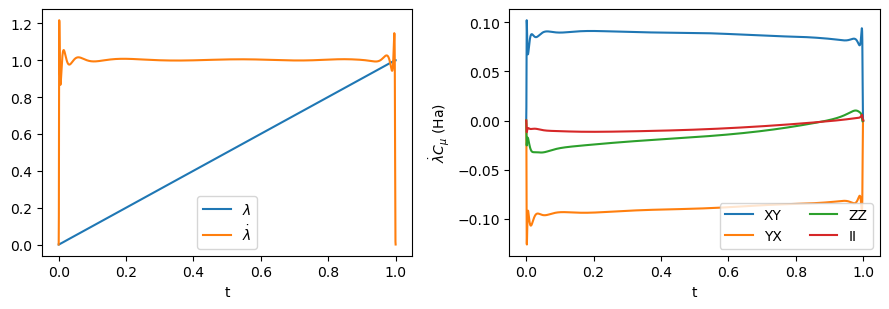

In [3]:
names = pauli_strings(2)
fig, (left, right) = plt.subplots(1, 2, figsize=(9, 3.2))
left.plot(data["time"], data["schedule"], label=r"$\lambda$")
left.plot(data["time"], data["schedule_rate"], label=r"$\dot\lambda$")
left.set_xlabel("t")
left.legend()
for name in ("XY", "YX", "ZZ", "II"):
    index = names.index(name)
    right.plot(data["time"], data["schedule_rate"] * data["coefficients"][:, index], label=name)
right.set_xlabel("t")
right.set_ylabel(r"$\dot\lambda C_\mu$ (Ha)")
right.legend(ncol=2)
fig.tight_layout()

Propagate $i\,\partial_t\psi = H(t)\psi$ from the ground state of $H_{\mathrm{initial}}$ ($\hbar=1$, $t\in[0,1]$) and measure the population of the instantaneous ground state of $H_{\mathrm{AD}}(t)$.

   with CD: final ground population 1.000000, energy -1.101150 Ha
without CD: final ground population 0.972167, energy -1.069415 Ha
exact ground energy: -1.1011503802844667


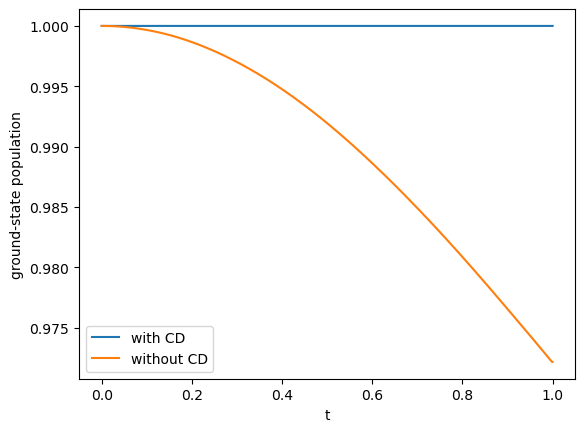

In [4]:
t = data["time"]
adiabatic = adiabatic_hamiltonian(data["schedule"], h_initial, h_final)
psi0 = np.linalg.eigh(h_initial)[1][:, 0]
for label, hamiltonians in (("with CD", data["hamiltonian"]), ("without CD", adiabatic)):
    states = propagate(t, hamiltonians, psi0)
    states /= np.linalg.norm(states, axis=1, keepdims=True)
    population = instantaneous_populations(states, adiabatic)[:, 0]
    energy = np.vdot(states[-1], h_final @ states[-1]).real
    plt.plot(t, population, label=label)
    print(f"{label:>10}: final ground population {population[-1]:.6f}, energy {energy:.6f} Ha")
print("exact ground energy:", np.linalg.eigvalsh(h_final)[0])
plt.xlabel("t")
plt.ylabel("ground-state population")
plt.legend();